[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GAI-Engineering/poc-learning-lab/blob/main/notebooks/05-group-chat-patterns/05-group-chat-patterns.ipynb)

# 05 · Three Ways to Run a Group Chat

**POC Learning Lab** — runnable reference notebooks for the multi-agent systems POC series.
*GAI Observe LLC · MIT (code) · CC BY 4.0 (text) · Synthetic data only · Deterministic stub model — no live model, no API key.*
*Disclosure: this notebook and its text were produced with AI assistance; every figure in it is checked against the recorded run evidence in this folder before release.*

## What you will learn
- Run one task under three routing shapes — round robin, selector, swarm — with the same agents.
- Count the mechanics of each parliament: turns, selector calls, handoffs — scripted counts that show what each shape does, not what a live system costs.
- Choose the routing before blaming the agents when a team misbehaves.

## How to use this notebook
Press **Run all** (Runtime ▸ Run all in Colab). Every cell runs in order; the results you see are produced live by the code above them — and the evidence section compares them with the recorded run evidence shipped in this repository. Work the exercises with the code, not just by reading.

**MODE: INTERIM (stub)** — the outcomes in this notebook come from a scripted demonstration and are labelled ILLUSTRATIVE; they are never quoted as findings. The FINAL target for every POC in this lab is a complete end-to-end run: a real model or tool, a recorded run transcript stored with the notebook, and figures nobody typed in (MEASURED). See the repository ROADMAP for each POC's mode and date.

## 1 · The idea

**Idea:** Turn a referral letter into a booked, prepared appointment — and show that the routing shape, not the agents, decides how the team behaves.
**Build steps:** (1) Three stub specialists (Summariser, Matcher, Scheduler) with crisp one-line descriptions. (2) Run the same referral task under round robin (fixed sequence), selector (a chair picks the next speaker from state) and swarm (direct handoffs, with a verification hand-back). (3) Record turns, selector calls, handoffs and total calls per mode in one comparison table. (4) Same prepared pack from all three modes — the difference is governance, not output.
**Guardrail:** Agents prepare and propose. Booking happens only on human confirmation — every run ends with the pack unbooked.
**Win condition:** One prepared pack from one letter, facts intact — and the builder can name which parliament they chose and what its mechanics spent in turns and calls (scripted counts from this demo, not prices).
Data: synthetic only. Model: deterministic stub, no live model.

## 2 · How it is built

Built: `poc/group_chat.py` using `kit/transcript.py` (one persisted transcript per mode).
Design: shared stub agents and shared state; only the router changes. Round robin runs the fixed sequence twice (6 turns — including turns the task did not need). The selector evaluates state before each turn (4 selector calls for 3 agent turns — the chair itself is a call, and in a live build a model call). The swarm hands off directly (4 turns, 3 handoffs, including the Scheduler → Summariser verification hand-back) — fewest calls in this script, and the least legible of the three transcripts.
Run: `python3 poc/group_chat.py` → `runs/run-01.txt` + `runs/transcript-<mode>.jsonl` ×3.

## 3 · Setup

No keys to configure. The POCs themselves run on the Python standard library. The evidence chart uses `pandas`/`matplotlib`: pre-installed in Colab; for a local run, `pip install -r requirements.txt` from the repository root first.

In [1]:
import json
from pathlib import Path

for _d in ("data", "runs"):
    Path(_d).mkdir(exist_ok=True)
_input_path = Path("data/letter.json")
if not _input_path.exists():
    _input_path.write_text('{\n  "patient": "Patient A (synthetic)",\n  "referrer": "GP practice (synthetic)",\n  "reason": "persistent knee pain, 6 weeks, physio completed without improvement",\n  "requested": "orthopaedics assessment",\n  "urgency": "routine"\n}\n', encoding="utf-8")
    print('input data materialized from the copy embedded in this notebook (in the repository it ships as data/letter.json)')

print('setup ok — standard library only for the POC itself')

setup ok — standard library only for the POC itself


## 4 · The shared kit (inlined)

The repository keeps these primitives once, in `kit/`, and every POC reuses them. They are inlined here so this notebook runs standalone in Colab — the code is identical to the kit source.

In [2]:
# --- from the shared kit: kit/transcript.py ---
"""Transcript store: the transcript IS the state (POC 02 pattern)."""
import json
from pathlib import Path

class TranscriptStore:
    def __init__(self):
        self.messages = []
    def append(self, speaker, kind, content):
        msg = {"turn": len(self.messages) + 1, "speaker": speaker, "kind": kind, "content": content}
        self.messages.append(msg)
        return msg
    def save_jsonl(self, path):
        Path(path).write_text("\n".join(json.dumps(m) for m in self.messages) + "\n")
    def __len__(self):
        return len(self.messages)

## 5 · The implementation

The complete POC, exactly as shipped in `poc/` in this repository (file-writing paths adjusted for the notebook, noted inline; the `__main__` guard is replaced by the Run cell below).

In [3]:
"""POC 05 - Three Ways to Run a Group Chat.
One task (turn a synthetic referral letter into a prepared appointment
pack) run under three routing shapes: round robin (a queue), selector
(a chair) and swarm (a corridor of handoffs). Same agents, same task -
the routing is the difference, so the comparison table is the lesson.
Deterministic stub agents: no live model. The letter is read from
data/letter.json - the data file is the single source for the run.
Agents prepare and propose; booking happens only on human confirmation.
The counts this run prints are the mechanics of THIS script (round
robin runs its sequence twice by construction; the swarm takes a
verification hand-back by construction). They show what each shape
does in the demo - they are not evidence of what a live system would
cost, earn, or how hard a real trace would be.
"""
import csv
import json
import sys
from pathlib import Path

MAX_TURNS = 12  # enforced cap for the selector and swarm loops


def load_letter(path):
    """Load the synthetic referral letter from its data file."""
    return json.loads(Path(path).read_text(encoding="utf-8"))


def summariser(state):
    letter = state["letter"]
    state["summary"] = f"{letter['reason']}; requested: {letter['requested']}"
    return "summary written"


def matcher(state):
    state["specialty"] = "orthopaedics" if "knee" in state.get("summary", "") else "general"
    return f"specialty = {state['specialty']}"


def scheduler(state):
    state["slots"] = ["Tue 09:30", "Wed 14:10"] if state.get("specialty") else []
    return f"slots proposed: {state['slots']} (unbooked - awaiting human confirmation)"


AGENTS = {"Summariser": summariser, "Matcher": matcher, "Scheduler": scheduler}
ORDER = ["Summariser", "Matcher", "Scheduler"]


def finish(state):
    return {"specialty": state.get("specialty"), "slots": state.get("slots", []),
            "booked": False, "note": "prepared pack only - booking requires human confirmation"}


def run_round_robin(letter):
    t, state = TranscriptStore(), {"letter": letter}
    for _ in range(2):  # fixed sequence, run twice whether needed or not - that is the queue's cost
        for name in ORDER:
            t.append(name, "turn", AGENTS[name](state))
    return t, finish(state), {"selector_calls": 0, "handoffs": 0}


def choose_next(state):
    """The chair's rule: the first missing piece decides who speaks."""
    return ("Summariser" if "summary" not in state else
            "Matcher" if "specialty" not in state else
            "Scheduler" if "slots" not in state else None)


def run_selector(letter, chooser=choose_next, max_turns=MAX_TURNS):
    """The chair decides who speaks next, from state. The turn cap is
    enforced inside the loop: a router that never finishes (a failed
    router) hits the cap and the run ends INCOMPLETE instead of
    looping forever."""
    t, state = TranscriptStore(), {"letter": letter}
    selector_calls = 0
    turns = 0
    while turns < max_turns:
        selector_calls += 1
        nxt = chooser(state)
        if nxt is None:
            break
        turns += 1
        t.append("Selector", "route", f"next speaker: {nxt}")
        t.append(nxt, "turn", AGENTS[nxt](state))
    else:
        t.append("Selector", "termination",
                 f"turn cap {max_turns} reached - router never finished; run INCOMPLETE")
    return t, finish(state), {"selector_calls": selector_calls, "handoffs": 0}


def run_swarm(letter, max_turns=MAX_TURNS):
    t, state = TranscriptStore(), {"letter": letter}
    handoffs = 0
    current = "Summariser"
    steps = 0
    while current is not None and steps < max_turns:  # each agent hands off directly - no chair, no queue
        steps += 1
        t.append(current, "turn", AGENTS[current](state))
        nxt = {"Summariser": "Matcher", "Matcher": "Scheduler", "Scheduler": "Summariser"}.get(current)
        if current == "Summariser" and "verified" in state:
            nxt = None
        if current == "Scheduler":
            state["verified"] = True  # scheduler hands back to summariser for a verification pass
        if nxt:
            handoffs += 1
            t.append(current, "handoff", f"hands off to {nxt}")
        current = nxt
    return t, finish(state), {"selector_calls": 0, "handoffs": handoffs}


def run_all(letter):
    """Run all three shapes over the same letter; every figure in the
    returned rows is counted from the run records, never typed in."""
    transcripts, rows = {}, []
    for mode, runner in [("round-robin", run_round_robin), ("selector", run_selector),
                         ("swarm", run_swarm)]:
        t, outcome, meta = runner(letter)
        transcripts[mode] = t
        agent_turns = sum(1 for m in t.messages if m["kind"] == "turn")
        total_calls = agent_turns + meta["selector_calls"]
        rows.append({"mode": mode, "agent_turns": agent_turns,
                     "selector_calls": meta["selector_calls"], "handoffs": meta["handoffs"],
                     "total_calls": total_calls,
                     "outcome": "pack prepared" if outcome["specialty"] else "INCOMPLETE",
                     "specialty": outcome["specialty"], "slots": outcome["slots"]})
    return transcripts, rows


def main():
    base = Path(".")  # notebook context: this folder (the notebook folder in the repo)
    letter = load_letter(base / "data" / "letter.json")
    transcripts, rows = run_all(letter)
    for mode, t in transcripts.items():
        t.save_jsonl(base / "runs" / f"transcript-{mode}.jsonl")
    with open(base / "runs" / "routing-comparison.csv", "w", newline="", encoding="utf-8") as fh:
        w = csv.writer(fh)
        w.writerow(["mode", "agent_turns", "selector_calls", "handoffs", "total_calls", "outcome"])
        for r in rows:
            w.writerow([r["mode"], r["agent_turns"], r["selector_calls"], r["handoffs"],
                        r["total_calls"], r["outcome"]])
    for r in rows:
        print(f"{r['mode']}: turns={r['agent_turns']} selector_calls={r['selector_calls']} "
              f"handoffs={r['handoffs']} total_calls={r['total_calls']} outcome={r['outcome']}")
    prepared = [r for r in rows if r["outcome"] == "pack prepared"]
    if len(prepared) == len(rows) and len({r["specialty"] for r in rows}) == 1:
        r0 = rows[0]
        print(f"All three modes prepared the same pack (specialty {r0['specialty']}, "
              f"{len(r0['slots'])} slots, unbooked).")
    else:
        print("Modes did NOT all prepare the pack: " +
              ", ".join(f"{r['mode']}={r['outcome']}" for r in rows) + ".")
    print("These counts are the mechanics of this script - round robin runs its sequence twice "
          "by construction and the swarm takes a verification hand-back by construction. They "
          "show what each shape does in the demo, not what a live routing mode costs or how "
          "hard a real path is to trace.")

## 6 · Run it

In [4]:
main()

round-robin: turns=6 selector_calls=0 handoffs=0 total_calls=6 outcome=pack prepared
selector: turns=3 selector_calls=4 handoffs=0 total_calls=7 outcome=pack prepared
swarm: turns=4 selector_calls=0 handoffs=3 total_calls=4 outcome=pack prepared
All three modes prepared the same pack (specialty orthopaedics, 2 slots, unbooked).
These counts are the mechanics of this script - round robin runs its sequence twice by construction and the swarm takes a verification hand-back by construction. They show what each shape does in the demo, not what a live routing mode costs or how hard a real path is to trace.


## 7 · See the evidence

The chart is drawn from the run's own results table (`runs/routing-comparison.csv` in the repository, written by the Run cell above). The recorded table is embedded below as a clearly labelled fallback for readers who have not run the cells.

chart data: this session's run (runs/routing-comparison.csv, written by the Run cell above)
       mode  agent_turns  selector_calls  handoffs  total_calls       outcome
round-robin            6               0         0            6 pack prepared
   selector            3               4         0            7 pack prepared
      swarm            4               0         3            4 pack prepared


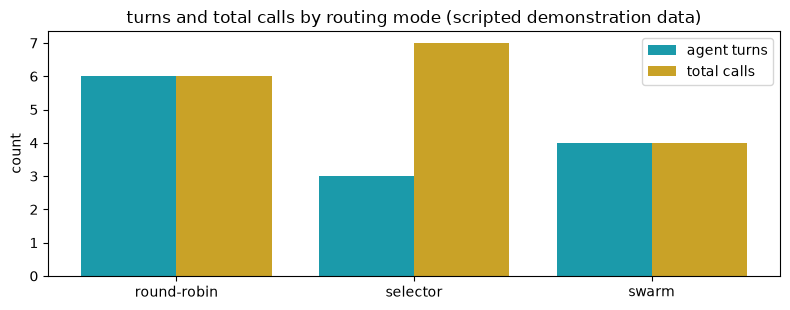

In [5]:
import io
import warnings
warnings.filterwarnings('ignore')  # keep library warnings out of stored outputs (QA-7)
import pandas as pd
import matplotlib.pyplot as plt

RECORDED_CSV = """mode,agent_turns,selector_calls,handoffs,total_calls,outcome
round-robin,6,0,0,6,pack prepared
selector,3,4,0,7,pack prepared
swarm,4,0,3,4,pack prepared"""

csv_file = Path("runs/routing-comparison.csv")
if csv_file.exists():
    text = csv_file.read_text()
    print("chart data: this session's run (runs/routing-comparison.csv, written by the Run cell above)")
else:
    text = RECORDED_CSV
    print("chart data: the RECORDED run shipped in the repository (the Run cell has not been executed in this session)")
df = pd.read_csv(io.StringIO(text))
print(df.to_string(index=False))

CHART_MODE = "routing"
if CHART_MODE == "attempts":
    colors = ["#C1666B" if o == "ERROR" else ("#C9A227" if o == "EMPTY" else "#1B9AAA") for o in df["outcome"]]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    bars = ax.bar(df["attempt"], [1] * len(df), color=colors)
    for rect, outcome in zip(bars, df["outcome"]):
        ax.text(rect.get_x() + rect.get_width() / 2, 0.5, outcome, ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.set_yticks([]); ax.set_xlabel("attempt"); ax.set_ylabel("outcome")
    ax.set_title("attempts by outcome (scripted demonstration data; teal SUCCESS, red ERROR, gold EMPTY)")
elif CHART_MODE == "routing":
    x = range(len(df))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar([i - 0.2 for i in x], df["agent_turns"], width=0.4, color="#1B9AAA", label="agent turns")
    ax.bar([i + 0.2 for i in x], df["total_calls"], width=0.4, color="#C9A227", label="total calls")
    ax.set_xticks(list(x)); ax.set_xticklabels(df["mode"]); ax.set_ylabel("count"); ax.legend()
    ax.set_title("turns and total calls by routing mode (scripted demonstration data)")
else:  # debate
    x = range(len(df))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar([i - 0.2 for i in x], df["pro_strength"], width=0.4, color="#1B9AAA", label="pro strength")
    ax.bar([i + 0.2 for i in x], df["con_strength"], width=0.4, color="#C1666B", label="con strength")
    ax.set_xticks(list(x)); ax.set_xticklabels(df["claim"] + " (" + df["verdict"] + ")")
    ax.set_ylabel("scripted argument strength"); ax.legend()
    ax.set_title("debate strength by claim (scripted demonstration data)")
plt.tight_layout()
plt.show()

## 8 · Recorded run evidence

What the reference run produced in the repository, labelled by provenance: **ILLUSTRATIVE** for scripted demonstrations (outcomes fixed in the script — the pattern is the lesson) and **MEASURED** only for outcomes nobody typed in. Your live run above should reproduce the recorded figures exactly — if it does not, that disagreement is itself the lesson: find it before you believe either.

Label: **ILLUSTRATIVE** — scripted demonstration: from `runs/run-01.txt` (executed 2026-10-26, deterministic stubs, synthetic referral letter); the agents' behaviours are scripted, so the counts are the mechanics of this script for each routing shape — against live agents this is where measured turn/cost data would land.

- Round robin: 6 agent turns, 0 selector calls, 0 handoffs, 6 total calls — pack prepared.
- Selector: 3 agent turns, 4 selector calls, 0 handoffs, 7 total calls — pack prepared. Fewest turns, most calls: in this script the chair spends a routing decision on every turn, including the final stop-check.
- Swarm: 4 agent turns, 0 selector calls, 3 handoffs, 4 total calls — pack prepared, including a verification hand-back.
- All three modes produced the same pack (specialty: orthopaedics; slots Tue 09:30 / Wed 14:10; booked: false — human confirmation required).
- Input: `data/letter.json` — the letter the run reads. Results: `runs/routing-comparison.csv`, written by the run itself (ILLUSTRATIVE). Chart: drawn in the notebook from the run's own results table (ILLUSTRATIVE).

## 9 · Exercises

1. Add a fourth specialist (a Records checker who verifies the letter's facts before scheduling). Which routing shape absorbs the new member with the fewest added mechanics — and which needs its router rewritten?
2. Make the Matcher fail once (return no specialty). Every mode must report INCOMPLETE — computed from its run, never a prepared pack (tests/test_perturbation.py runs this case). Trace what each shape does next, from its transcript. Which failure is easiest to audit?
3. The selector spent 4 calls to route 3 turns in this script. In a live system each selector call is a model call — at what team size might the chair pay for itself? Argue it from the mechanics, and name what you would have to measure live before believing the argument.

## 10 · Recap

Same agents, same task, three different systems — because routing is governance. A queue is predictable and spends turns it does not need, a chair spends a routing decision on every turn, a corridor spends handoffs and leaves the thinnest transcript. Name your parliament before you judge your agents.

---
*Next in the series: see the repository index. Questions and corrections are welcome via the repo's Issues — this is a learning artefact, and it improves in public.*